In [ ]:

!pip -q install xgboost

import pandas as pd
import numpy as np
import os
import zipfile
import io
import joblib
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Upload dataset
uploaded = files.upload()

# Read CSV or ZIP file
csv_files = []

for filename, content in uploaded.items():
    if filename.lower().endswith(".csv"):
        csv_files.append((filename, content))
    elif filename.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for name in z.namelist():
                if name.lower().endswith(".csv") and not name.startswith("__MACOSX"):
                    csv_files.append((name, z.read(name)))

if not csv_files:
    raise ValueError("Please upload a CSV file or a ZIP containing CSV files.")

print("Available datasets:")
for name, content in csv_files:
    print(name)

# Select training data by checking for target column
target_names = ["Genetic Disorder", "Genetic_Disorder", "Disorder"]
df = None
target = None

for name, content in csv_files:
    temp = pd.read_csv(io.BytesIO(content))
    temp.columns = temp.columns.str.strip()
    found = next((c for c in target_names if c in temp.columns), None)
    if found:
        df, target = temp, found
        break

if df is None:
    print("\nYour uploaded file has no target column.")
    print("This appears to be test data. Upload the TRAINING CSV too.")
    print("A trained model cannot be created from test data alone.")
else:
    df = df.drop_duplicates()
    df = df.dropna(subset=[target]).copy()

    remove = [
        c for c in df.columns
        if c.lower().replace(" ", "_") in
        ["patient_id", "id", "patient_first_name", "family_name"]
    ]

    X = df.drop(columns=[target] + remove)
    y_text = df[target].astype(str)
    encoder = LabelEncoder()
    y = encoder.fit_transform(y_text)

    if len(encoder.classes_) < 2:
        raise ValueError("Training data must contain at least two target classes.")

    numeric = X.select_dtypes(include=np.number).columns.tolist()
    categorical = X.select_dtypes(exclude=np.number).columns.tolist()

    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = Pipeline([
        ("prep", prep),
        ("xgb", XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.1,
            eval_metric="mlogloss",
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\nModel trained successfully!")
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("\nClassification Report:")
    print(classification_report(
        y_test, pred,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_,
        zero_division=0
    ))

    joblib.dump({
        "model": model,
        "label_encoder": encoder
    }, "/content/genetic_disorder_xgboost.pkl")

    print("Model saved successfully!")

    # Predict uploaded test data, if available
    for name, content in csv_files:
        test_df = pd.read_csv(io.BytesIO(content))
        test_df.columns = test_df.columns.str.strip()

        if name != df.attrs.get("source_name", "") and target not in test_df.columns:
            test_X = test_df.drop(columns=[
                c for c in test_df.columns
                if c.lower().replace(" ", "_") in
                ["patient_first_name", "family_name"]
            ], errors="ignore")

            test_X = test_X.reindex(columns=X.columns)
            probabilities = model.predict_proba(test_X)
            predicted = encoder.inverse_transform(
                probabilities.argmax(axis=1)
            )
            confidence = probabilities.max(axis=1)

            results = pd.DataFrame({
                "Predicted Category": predicted,
                "Probability": confidence,
                "Priority Level": np.where(
                    confidence >= 0.75, "High",
                    np.where(confidence >= 0.45, "Medium", "Low")
                )
            })

            results.to_csv(
                "/content/patient_priority_results.csv", index=False
            )
            print("\nPredictions saved to patient_priority_results.csv")
            break


Saving train_genetic_disorders.csv to train_genetic_disorders (1).csv
Available datasets:
train_genetic_disorders (1).csv

Model trained successfully!
Accuracy: 0.9533

Classification Report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.92      1.00      0.96      1938
Multifactorial genetic inheritance disorders       1.00      0.92      0.95       404
            Single-gene inheritance diseases       1.00      0.90      0.95      1451

                                    accuracy                           0.95      3793
                                   macro avg       0.97      0.94      0.95      3793
                                weighted avg       0.96      0.95      0.95      3793

Model saved successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test_genetic_disorders.csv.zip to test_genetic_disorders.csv (2).zip


In [ ]:
import zipfile
import pandas as pd
import numpy as np

# Extract test CSV from ZIP
zip_path = "/content/test_genetic_disorders.csv (2).zip"

with zipfile.ZipFile(zip_path) as z:
    csv_name = next(n for n in z.namelist() if n.endswith(".csv"))
    test_df = pd.read_csv(z.open(csv_name))

# Load trained model
checkpoint = joblib.load("/content/genetic_disorder_xgboost.pkl")
model = checkpoint["model"]
label_encoder = checkpoint["label_encoder"]

# Prepare test data
test_df.columns = test_df.columns.str.strip()
test_X = test_df.drop(columns=[
    c for c in test_df.columns
    if c.lower().replace(" ", "_") in
    ["patient_first_name", "family_name", "patient_id", "id"]
], errors="ignore")

# Match training features
test_X = test_X.reindex(columns=X.columns)

# Predict
probs = model.predict_proba(test_X)
predictions = label_encoder.inverse_transform(probs.argmax(axis=1))
confidence = probs.max(axis=1)

results = pd.DataFrame({
    "Predicted Category": predictions,
    "Probability": np.round(confidence, 4),
    "Priority Level": np.where(
        confidence >= 0.75, "High",
        np.where(confidence >= 0.45, "Medium", "Low")
    )
})

results.to_csv("/content/patient_priority_results.csv", index=False)

print("Predictions completed!")
print(results.head(10))
print("\nPriority counts:")
print(results["Priority Level"].value_counts())

files.download("/content/patient_priority_results.csv")

Predictions completed!
                            Predicted Category  Probability Priority Level
0  Mitochondrial genetic inheritance disorders       0.7414         Medium
1  Mitochondrial genetic inheritance disorders       0.9310           High
2  Mitochondrial genetic inheritance disorders       0.8824           High
3  Mitochondrial genetic inheritance disorders       0.9042           High
4  Mitochondrial genetic inheritance disorders       0.8758           High
5  Mitochondrial genetic inheritance disorders       0.8215           High
6  Mitochondrial genetic inheritance disorders       0.9472           High
7  Mitochondrial genetic inheritance disorders       0.7720           High
8  Mitochondrial genetic inheritance disorders       0.8856           High
9  Mitochondrial genetic inheritance disorders       0.9172           High

Priority counts:
Priority Level
High      8622
Medium     840
Low          1
Name: count, dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

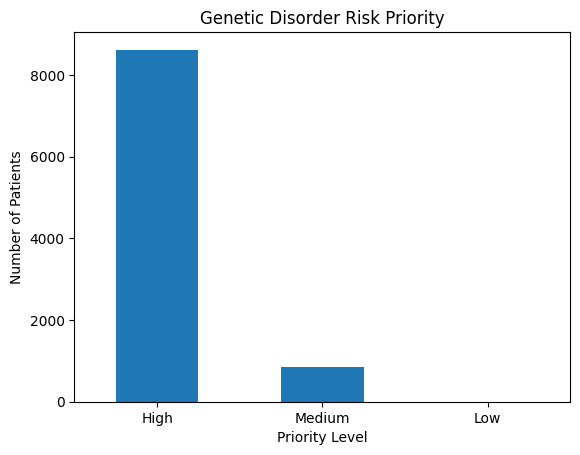

In [ ]:
import matplotlib.pyplot as plt

results["Priority Level"].value_counts().reindex(
    ["High", "Medium", "Low"], fill_value=0
).plot(kind="bar")

plt.title("Genetic Disorder Risk Priority")
plt.xlabel("Priority Level")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Genetic Disorder Risk Dashboard",
    page_icon="🧬",
    layout="wide"
)

st.title("🧬 Genetic Disorder Risk Prioritization")
st.write("AI-based genetic disorder risk prediction dashboard")

# Load prediction results
df = pd.read_csv("/content/patient_priority_results.csv")

# Summary metrics
total = len(df)
high = (df["Priority Level"] == "High").sum()
medium = (df["Priority Level"] == "Medium").sum()
low = (df["Priority Level"] == "Low").sum()

c1, c2, c3, c4 = st.columns(4)

c1.metric("Total Records", total)
c2.metric("High Priority", high)
c3.metric("Medium Priority", medium)
c4.metric("Low Priority", low)

st.subheader("Priority Distribution")

counts = df["Priority Level"].value_counts().reindex(
    ["High", "Medium", "Low"], fill_value=0
)

st.bar_chart(counts)

st.subheader("Patient Prediction Results")

search = st.text_input("Search by predicted category")

if search:
    df = df[df["Predicted Category"].str.contains(
        search, case=False, na=False
    )]

st.dataframe(df, use_container_width=True)

st.download_button(
    "Download Results CSV",
    data=df.to_csv(index=False),
    file_name="patient_priority_results.csv",
    mime="text/csv"
)

st.caption(
    "Educational project only. Predictions are not a medical diagnosis."
)

Writing app.py


In [ ]:
!pip -q install streamlit

In [ ]:
!streamlit run app.py &>/content/streamlit.log &

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸
added 22 packages in 3s
⠸
⠸3 packages are looking for funding
⠸  run `npm fund` for details
⠸

In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼your url is: https://salty-lizards-grab.loca.lt
^C


In [ ]:
!curl -s https://loca.lt/mytunnelpassword

34.81.116.14

In [ ]:
!cat /content/streamlit.log



2026-10-25 09:40:22.415 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501

  Stopping...


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0



2026-10-25 09:49:25.740 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501

  Stopping...


In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼your url is: https://slow-singers-sink.loca.lt
^C


In [ ]:
!curl -s https://loca.lt/mytunnelpassword

34.81.116.14

In [ ]:
!cat /content/streamlit.log



2026-10-25 09:40:22.415 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501

  Stopping...


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!sleep 3; cat /content/streamlit.log



2026-10-25 09:52:33.301 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501



In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://rare-spoons-guess.loca.lt
^C


In [ ]:
!curl -s https://loca.lt/mytunnelpassword

34.81.116.14

In [ ]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!sleep 3; curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sun, 25 Oct 2026 09:55:09 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 25 Oct 2026 09:40:03 GMT
etag: "e954c2466eaf158f5ef4e43560fedf1a"
cache-control: no-cache



In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴your url is: https://fruity-spies-smile.loca.lt
^C


In [ ]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0



2026-10-25 10:00:08.891 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501

  Stopping...


In [ ]:
!curl -I http://localhost:8501

curl: (7) Failed to connect to localhost port 8501 after 0 ms: Couldn't connect to server


In [ ]:
!cat /content/streamlit.log



2026-10-25 09:55:01.337 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.81.116.14:8501

2026-10-25 09:56:21.827 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-10-25 09:56:44.452 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
  Stopping...


In [ ]:
!nohup streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 < /dev/null &

In [ ]:
!sleep 5; curl -I http://localhost:8501

HTTP/1.1 200 OK
date: Sun, 25 Oct 2026 10:01:24 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 25 Oct 2026 09:40:03 GMT
etag: "e954c2466eaf158f5ef4e43560fedf1a"
cache-control: no-cache



In [ ]:
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏your url is: https://cute-peas-battle.loca.lt
^C


In [ ]:
from google.colab import files
files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/patient_priority_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/requirements.txt
streamlit
pandas
matplotlib

Writing /content/requirements.txt


In [ ]:
from google.colab import files
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>